# Binary Logistic Regression in `R`

## The `heartdisease` Dataset
...
We will subset these data to only the `cleveland` site and then define a new binary outcome variable based upon the outcome of an angiograph to indicate either the absence or presence of heart disease.

In [1]:
library('datarium')
data('heartdisease')

cleveland         <- subset(heartdisease, dataset == "cleveland")
cleveland$disease <- as.integer(cleveland$num > 0)
cleveland$sex     <- as.factor(cleveland$sex)

## Fitting the Model

In [2]:
mod <- glm(disease ~ age + sex, family=binomial(link=logit), data=cleveland)
summary(mod)


Call:
glm(formula = disease ~ age + sex, family = binomial(link = logit), 
    data = cleveland)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept) -4.80775    0.89816  -5.353 8.66e-08 ***
age          0.06571    0.01484   4.427 9.56e-06 ***
sex1         1.49887    0.28940   5.179 2.23e-07 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 417.98  on 302  degrees of freedom
Residual deviance: 372.31  on 300  degrees of freedom
AIC: 378.31

Number of Fisher Scoring iterations: 4


## Model Diagnostics

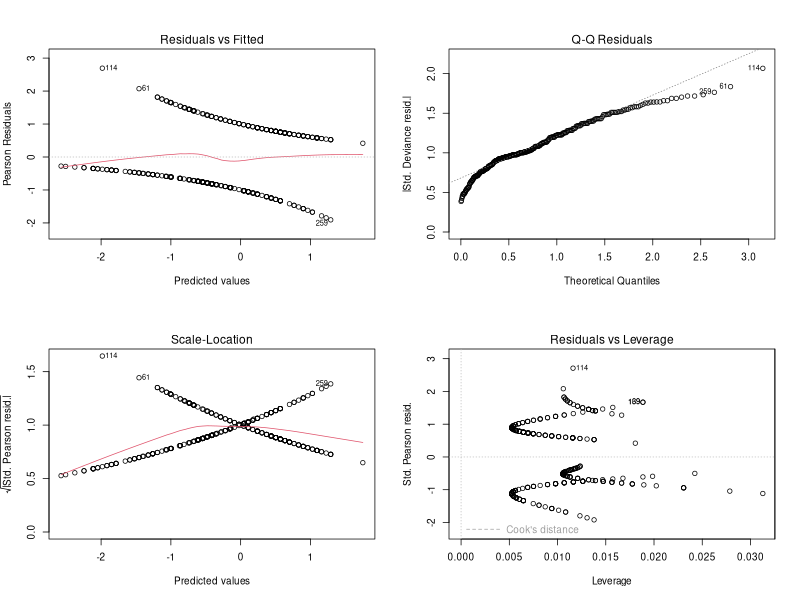

In [3]:
par(mfrow=c(2,2))
plot(mod)
par(mfrow=c(1,1))

## Inference on the Effects

## Plotting the Effects

Loading required package: carData
lattice theme set by effectsTheme()
See ?effectsTheme for details.


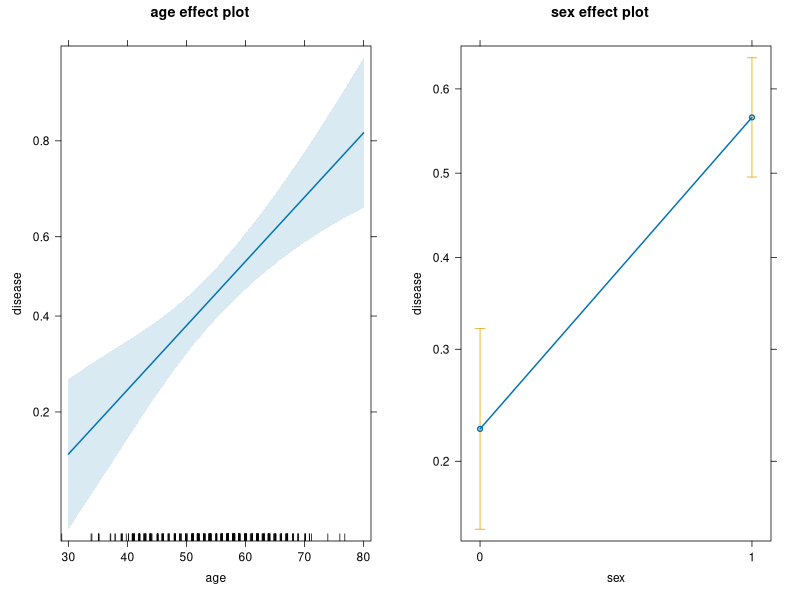

In [4]:
library('effects')
plot(allEffects(mod))

Notice that the `effects` package is smart enough to recognise that this is a logistic regression model and thus has transformed the prediction on to the probability scale for ease of interpretation.